# ДЗ1
Used Car Prices

Задача предсказать цену подержанного автомобиля

## Гипотезы (до анализа)
1. Пробег сильнее связан с годом выпуска, чем  с ценой.
2. Без зарегистрированных ДТП медианная цена минимум на 20% выше.
3. Добавление марки автомобиля увеличит CV R² минимум на 0,1.
4. Топливо и ДТП дадут меньший прирост CV R², чем марка.
5. Увеличение alpha в Ridge с 1 до 10 улучшит CV R².
6. Random Forest уменьшит MAE минимум на 5% по сравнению с Ridge.

## 1. Данные и EDA

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [19]:
df = pd.read_csv('used_cars.csv')
df = df.drop_duplicates()
print('Размер:', df.shape)

print(df[:1])
for col in ['milage', 'price']:
    df[col] = pd.to_numeric(df[col].str.replace(r'[^0-9.]', '', regex=True), errors='coerce')
df = df.dropna(subset=['price'])
print()
print(df[:1])

Размер: (4009, 12)
  brand                            model  model_year      milage  \
0  Ford  Utility Police Interceptor Base        2013  51,000 mi.   

       fuel_type                                             engine  \
0  E85 Flex Fuel  300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...   

  transmission ext_col int_col                                accident  \
0  6-Speed A/T   Black   Black  At least 1 accident or damage reported   

  clean_title    price  
0         Yes  $10,300  

  brand                            model  model_year   milage      fuel_type  \
0  Ford  Utility Police Interceptor Base        2013  51000.0  E85 Flex Fuel   

                                              engine transmission ext_col  \
0  300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...  6-Speed A/T   Black   

  int_col                                accident clean_title  price  
0   Black  At least 1 accident or damage reported         Yes  10300  


In [20]:
print(df[['model_year', 'milage', 'price']].describe())
print('\nПропуски:')
print(df.isna().sum())

        model_year         milage         price
count  4009.000000    4009.000000  4.009000e+03
mean   2015.515590   64717.551010  4.455319e+04
std       6.104816   52296.599459  7.871064e+04
min    1974.000000     100.000000  2.000000e+03
25%    2012.000000   23044.000000  1.720000e+04
50%    2017.000000   52775.000000  3.100000e+04
75%    2020.000000   94100.000000  4.999000e+04
max    2024.000000  405000.000000  2.954083e+06

Пропуски:
brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64


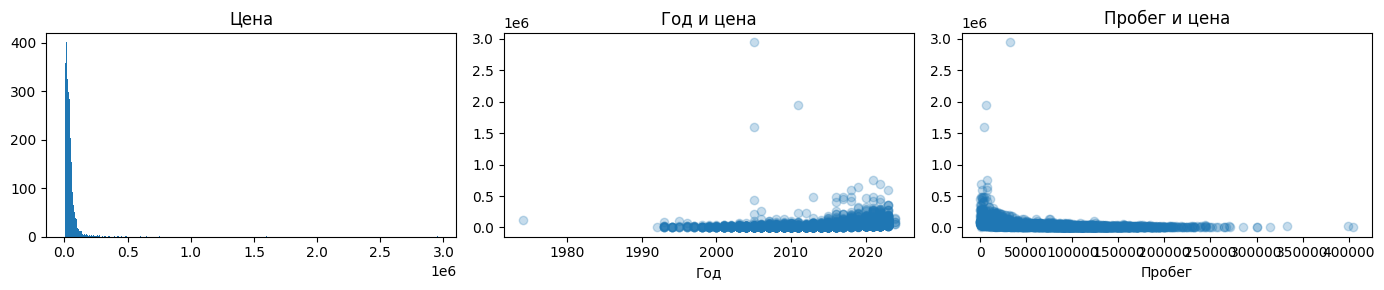

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3))

ax[0].hist(df['price'], bins=600)
ax[0].set(title='Цена')

ax[1].scatter(df['model_year'], df['price'], alpha=0.25)
ax[1].set(title='Год и цена', xlabel='Год')

ax[2].scatter(df['milage'], df['price'], alpha=0.25)
ax[2].set(title='Пробег и цена', xlabel='Пробег')

plt.tight_layout()

In [22]:
print(df[['model_year', 'milage', 'price']].corr())
print('\nМедианная цена по истории ДТП:')
print(df.groupby('accident')['price'].median())

            model_year    milage     price
model_year    1.000000 -0.617720  0.199496
milage       -0.617720  1.000000 -0.305528
price         0.199496 -0.305528  1.000000

Медианная цена по истории ДТП:
accident
At least 1 accident or damage reported    20900.0
None reported                             35667.5
Name: price, dtype: float64


**Гипотеза 1:** подтвердилась: (по модулю -0.62 > -0.31).

**Гипотеза 2:** подтвердилась: медиана без ДТП 35668, с ДТП 20900 (на 71% выше)

## 2. Подготовка и отбор признаков

In [23]:
train, test = train_test_split(df, test_size=0.2, random_state=42)
y_train, y_test = train['price'], test['price']

feature_sets = [
    ['model_year', 'milage'],
    ['model_year', 'milage', 'brand'],
    ['model_year', 'milage', 'brand', 'fuel_type'],
    ['model_year', 'milage', 'brand', 'fuel_type', 'accident']
]

for cols in feature_sets:
    X = pd.get_dummies(train[cols], dummy_na=True, dtype=int)
    score = cross_val_score(make_pipeline(MinMaxScaler(), Ridge(alpha=1)), X, y_train, cv=3, scoring='r2').mean()
    print(cols[-1], round(score, 3))

features = feature_sets[-1]
X_train = pd.get_dummies(train[features], dummy_na=True, dtype=int)
X_test = pd.get_dummies(test[features], dummy_na=True, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

milage 0.206
brand 0.565
fuel_type 0.57
accident 0.572


**Гипотеза 3:** подтвердилась: добавление марки повысило CV R² с 0.206 до 0.565

**Гипотеза 4:** подтвердилась: топливо и ДТП вместе добавили только 0.006, марка 0.359

## 3. Модели и метрики

In [26]:
models = {
    'Linear Regression': make_pipeline(MinMaxScaler(), LinearRegression()),
    'Ridge': GridSearchCV(
        make_pipeline(MinMaxScaler(), Ridge()),
        {'ridge__alpha': [0.1, 1, 10, 100]},
        cv=3, scoring='r2'
    ),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(name,
          'MAE:', round(mean_absolute_error(y_test, pred)),
          'RMSE:', round(np.sqrt(mean_squared_error(y_test, pred))),
          'R2:', round(r2_score(y_test, pred), 3))

ridge = models['Ridge']
print('Лучший alpha:', ridge.best_params_['ridge__alpha'])
for alpha, score in zip([0.1, 1, 10, 100], ridge.cv_results_['mean_test_score']):
    print('alpha:', alpha, 'CV R2:', round(score, 3))

Linear Regression MAE: 25392 RMSE: 138297 R2: 0.064
Ridge MAE: 25382 RMSE: 138280 R2: 0.064
Random Forest MAE: 22830 RMSE: 135122 R2: 0.107
Лучший alpha: 0.1
alpha: 0.1 CV R2: 0.573
alpha: 1 CV R2: 0.572
alpha: 10 CV R2: 0.477
alpha: 100 CV R2: 0.229


## 4. Выводы
Гипотеза 5: не подтвердилась: при alpha=10 CV R² = 0,479, при alpha=1 — 0,571.

Гипотеза 6: подтвердилась: Random Forest уменьшил MAE на 10% (22 841 против 25 423 у Ridge).
